# N2 — Occlusion

N1a found no headroom on lighting corruption: hard Hamming already reached 99.43% from
ground-truth corners, mean Hamming 0.861. There was almost no damage to recover.

Occlusion is different. It destroys **contiguous, locatable** cells, which is what erasure
decoding is designed for. With minimum distance 12, ARUCO_MIP_36h12 corrects 5 errors but up
to 11 erasures, so the theoretical advantage is largest exactly here.

**Four decode rules, on identical decoder output:**
1. **hard Hamming** — threshold at 0.5, nearest codeword (what DeepArUco++ does)
2. **soft log-likelihood** — score codewords by the probabilities instead of rounding
3. **erasure (confidence)** — flag low-confidence cells as erasures
4. **erasure (oracle)** — flag the cells we *know* are occluded

Rule 4 is not deployable; it is the ceiling. The gap between 4 and 3 measures how much is lost
because the decoder cannot tell when it is blind — which is the contribution this notebook is
here to size.

**Prediction from a synthetic pre-test:** confidence in occluded cells stays at 0.995-0.999,
indistinguishable from clean cells, even at Hamming 6. If that reproduces on real data,
rule 3 collapses onto rule 1 and the gap to rule 4 is the whole story.

Requires N0. Occlusion is applied to **source frames**, then rectified with GT corners, so the
occluder undergoes the same perspective warp a real object would.

## 1. Setup

In [3]:
%pip install -q opencv-contrib-python==4.10.0.84 h5py
print(">>> If OpenCV was just installed, RESTART THE RUNTIME / KERNEL before continuing.")

Note: you may need to restart the kernel to use updated packages.
>>> If OpenCV was just installed, RESTART THE RUNTIME / KERNEL before continuing.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1b. Port module

In [1]:
%%writefile deeparuco_port.py
"""
Port the pretrained DeepArUco++ decoder from Keras .h5 to PyTorch, without TensorFlow.

The published decoder (models/dec_new.h5 in AVAuco/deeparuco) is a Keras 2.11 model:

    Input(32, 32, 1)
    Conv2D(8, 5x5, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(4, 3x3, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(1, 1x1, valid, sigmoid)   ->  (6, 6, 1)

Only h5py is needed to read the weights, so the repo's Python 3.9 + TensorFlow
environment is never required for baseline inference.

IMPORTANT PORTING DETAIL
    Keras PReLU defaults to shared_axes=None, so alpha is PER-ELEMENT, not per-channel:
    the stored alphas have shape (28, 28, 8) and (12, 12, 4). torch.nn.PReLU only
    supports per-channel alpha, so using it here silently produces a different model.
    SpatialPReLU below keeps the full alpha tensor.

Layout conversions:
    Keras conv kernel (kh, kw, in, out) -> torch (out, in, kh, kw)
    Keras PReLU alpha (h, w, c)         -> torch (c, h, w)
    Keras 'valid' padding               -> torch padding=0

Usage:
    from deeparuco_port import load_weights, NumpyDecoder, TorchDecoder, verify_port
    verify_port('models/dec_new.h5')          # run this first, once
    dec = TorchDecoder.from_h5('models/dec_new.h5')
    probs = dec(x)                            # x: (N, 1, 32, 32) float in [0, 1]

Upstream code is AGPL-3.0. This module reads a weights file; it does not copy source.
Cite Berral-Soler et al., Image and Vision Computing 152 (2024) 105313.
"""

import numpy as np

DEFAULT_H5 = "models/dec_new.h5"


# --------------------------------------------------------------------------- weights

def load_weights(h5_path=DEFAULT_H5):
    """Read decoder weights from the Keras .h5. Returns a dict of numpy arrays."""
    import h5py

    store = {}
    with h5py.File(h5_path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset) and name.startswith("model_weights/"):
                store[name] = np.array(obj)
        f.visititems(visit)

    def pick(layer, suffix):
        hits = [k for k in store if f"/{layer}/" in k and k.endswith(suffix)]
        if len(hits) != 1:
            raise KeyError(f"expected one match for {layer}:{suffix}, got {hits}")
        return store[hits[0]]

    w = {
        "c1_w": pick("conv2d", "kernel:0"),   "c1_b": pick("conv2d", "bias:0"),
        "p1_a": pick("p_re_lu", "alpha:0"),
        "c2_w": pick("conv2d_1", "kernel:0"), "c2_b": pick("conv2d_1", "bias:0"),
        "p2_a": pick("p_re_lu_1", "alpha:0"),
        "c3_w": pick("conv2d_2", "kernel:0"), "c3_b": pick("conv2d_2", "bias:0"),
    }
    expect = {"c1_w": (5,5,1,8), "c1_b": (8,), "p1_a": (28,28,8),
              "c2_w": (3,3,8,4), "c2_b": (4,), "p2_a": (12,12,4),
              "c3_w": (1,1,4,1), "c3_b": (1,)}
    for k, shape in expect.items():
        assert w[k].shape == shape, f"{k}: got {w[k].shape}, expected {shape}"
    return w


# ------------------------------------------------------------------- numpy reference

class NumpyDecoder:
    """Reference implementation. Verified against synthetic markers: 4/5 exact."""

    def __init__(self, weights):
        self.w = weights

    @classmethod
    def from_h5(cls, path=DEFAULT_H5):
        return cls(load_weights(path))

    @staticmethod
    def _conv(x, w, b):
        kh, kw, _, co = w.shape
        H, W, _ = x.shape
        out = np.zeros((H - kh + 1, W - kw + 1, co), np.float32)
        for i in range(out.shape[0]):
            for j in range(out.shape[1]):
                out[i, j] = np.tensordot(
                    x[i:i+kh, j:j+kw, :], w, axes=([0, 1, 2], [0, 1, 2])) + b
        return out

    @staticmethod
    def _pool(x):
        h, w, c = x.shape
        return x.reshape(h // 2, 2, w // 2, 2, c).max(axis=(1, 3))

    def __call__(self, marker32):
        """marker32: (32, 32) float in [0, 1]. Returns (6, 6) bit probabilities."""
        w = self.w
        x = np.asarray(marker32, np.float32)[..., None]
        x = self._conv(x, w["c1_w"], w["c1_b"])
        x = np.where(x > 0, x, w["p1_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c2_w"], w["c2_b"])
        x = np.where(x > 0, x, w["p2_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c3_w"], w["c3_b"])
        return (1.0 / (1.0 + np.exp(-np.clip(x[..., 0], -60, 60)))).astype(np.float32)


# -------------------------------------------------------------------------- pytorch

def _torch():
    import torch
    import torch.nn as nn
    return torch, nn


class SpatialPReLU:
    """Created via _build so torch is imported lazily. See module docstring."""


def TorchDecoder_factory():
    torch, nn = _torch()

    class _SpatialPReLU(nn.Module):
        """Per-element PReLU, matching Keras PReLU(shared_axes=None)."""
        def __init__(self, alpha_chw):
            super().__init__()
            self.alpha = nn.Parameter(torch.tensor(alpha_chw, dtype=torch.float32))

        def forward(self, x):
            return torch.where(x > 0, x, self.alpha.unsqueeze(0) * x)

    class _TorchDecoder(nn.Module):
        def __init__(self, weights=None):
            super().__init__()
            self.c1 = nn.Conv2d(1, 8, 5)
            self.c2 = nn.Conv2d(8, 4, 3)
            self.c3 = nn.Conv2d(4, 1, 1)
            self.pool = nn.MaxPool2d(2)
            a1 = np.zeros((8, 28, 28), np.float32) if weights is None \
                 else np.transpose(weights["p1_a"], (2, 0, 1))
            a2 = np.zeros((4, 12, 12), np.float32) if weights is None \
                 else np.transpose(weights["p2_a"], (2, 0, 1))
            self.p1, self.p2 = _SpatialPReLU(a1), _SpatialPReLU(a2)
            if weights is not None:
                self.load_keras(weights)

        def load_keras(self, w):
            with torch.no_grad():
                for conv, kw, kb in ((self.c1, "c1_w", "c1_b"),
                                     (self.c2, "c2_w", "c2_b"),
                                     (self.c3, "c3_w", "c3_b")):
                    conv.weight.copy_(torch.tensor(np.transpose(w[kw], (3, 2, 0, 1))))
                    conv.bias.copy_(torch.tensor(w[kb]))

        @classmethod
        def from_h5(cls, path=DEFAULT_H5):
            return cls(load_weights(path))

        def forward(self, x):
            """x: (N, 1, 32, 32) in [0, 1]. Returns (N, 6, 6) bit probabilities."""
            x = self.pool(self.p1(self.c1(x)))
            x = self.pool(self.p2(self.c2(x)))
            return torch.sigmoid(self.c3(x)).squeeze(1)

    return _TorchDecoder


def __getattr__(name):
    if name == "TorchDecoder":
        return TorchDecoder_factory()
    raise AttributeError(name)


# --------------------------------------------------------------------------- verify

def verify_port(h5_path=DEFAULT_H5, n=16, tol=1e-4, verbose=True):
    """Assert the PyTorch port matches the numpy reference. Run once before use.

    The numpy path is validated; the torch path is validated against it here rather
    than assumed. Do not skip this.
    """
    torch, _ = _torch()
    w = load_weights(h5_path)
    ref = NumpyDecoder(w)
    net = TorchDecoder_factory()(w).eval()

    rng = np.random.default_rng(0)
    x = rng.random((n, 32, 32)).astype(np.float32)
    with torch.no_grad():
        got = net(torch.tensor(x).unsqueeze(1)).numpy()
    want = np.stack([ref(xi) for xi in x])

    err = float(np.abs(got - want).max())
    if verbose:
        print(f"port check: {n} random inputs, max abs difference {err:.2e} (tol {tol:g})")
    assert err < tol, f"PyTorch port disagrees with numpy reference (max diff {err:.2e})"
    if verbose:
        print("PyTorch port matches the numpy reference.")
    return err


def decode_ids(probs, id_to_bits, n_markers=250):
    """Hard-decision decode: nearest codeword by Hamming distance over 4 rotations.

    probs: (6, 6) bit probabilities. Returns (marker_id, rotation, hamming).
    Replace with soft log-likelihood decoding to use the confidences.
    """
    obs = (np.asarray(probs) > 0.5).astype(np.uint8)
    best = (None, None, 99)
    for mid in range(n_markers):
        ref = np.asarray(id_to_bits(mid), np.uint8).reshape(6, 6)
        for rot in range(4):
            h = int(np.sum(np.rot90(obs, rot) != ref))
            if h < best[2]:
                best = (mid, rot, h)
    return best


if __name__ == "__main__":
    import sys
    path = sys.argv[1] if len(sys.argv) > 1 else DEFAULT_H5
    w = load_weights(path)
    print("weights loaded:", {k: v.shape for k, v in w.items()})
    try:
        verify_port(path)
    except ImportError:
        print("torch not installed; numpy reference verified only")


Writing deeparuco_port.py


In [2]:
import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

# Colab: Google Drive. Local (VS Code / Jupyter): the same folder N0 used — ~/aruco_p2,
# or wherever the ARUCO_P2_BASE environment variable points.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE, WORK = '/content/drive/MyDrive/aruco_p2', '/content/work'
except ImportError:
    BASE = os.environ.get('ARUCO_P2_BASE',
                          os.path.join(os.path.expanduser('~'), 'aruco_p2')).replace('\\', '/')
    WORK = f'{BASE}/work'
ART = f'{BASE}/artifacts'
assert os.path.exists(f'{ART}/splits.json'), f'{ART}/splits.json missing — run N0 first'
os.makedirs(WORK, exist_ok=True)
sys.path.insert(0, os.getcwd())   # the previous cell writes deeparuco_port.py here
print(f'BASE: {BASE}\nWORK: {WORK}')

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/AVAuco/deeparuco.git',REPO],check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits
from deeparuco_port import load_weights, NumpyDecoder

SHADOW = f'{WORK}/shadow'
os.makedirs(SHADOW, exist_ok=True)
for i in range(1, 7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        tar = f'{BASE}/archives/video_{i}.tar.gz'
        assert os.path.exists(tar), f'{tar} missing — run N0 first'
        subprocess.run(['tar','-xzf',tar,'-C',SHADOW], check=True)

splits = json.load(open(f'{ART}/splits.json'))
DEV, HELDOUT, STRIDE = splits['dev'], splits['heldout'][0], splits['benchmark_stride']

# Guard against partial extraction or stub data: frame counts must match N0's manifest.
N0_FRAMES = json.load(open(f'{ART}/manifest.json'))['shadow_aruco']['frames']
for vid in DEV:
    n = len(glob.glob(f'{SHADOW}/{vid}/*.png'))
    assert n == N0_FRAMES[vid], f'{vid}: {n} frames on disk, N0 manifest says {N0_FRAMES[vid]}'

W = load_weights(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)
print('dev:', DEV, '| held out:', HELDOUT, '| stride:', STRIDE)

BASE: C:/Users/hp/aruco_p2
WORK: C:/Users/hp/aruco_p2/work
dev: ['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] | held out: video_6 | stride: 6


## 2. Batched decoder

Same weights, same arithmetic as `NumpyDecoder`, evaluated in batches. Verified against the
reference below — do not skip that assertion.

In [3]:
def _conv(x, w, b):
    kh, kw, _, _ = w.shape
    win = sliding_window_view(x, (kh, kw), axis=(1, 2))
    return np.einsum('nohckl,klci->nohi', win, w, optimize=True) + b

def _pool(x):
    N,H,Wd,Cc = x.shape
    return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))

def batch_decode(x32, chunk=2048):
    out = []
    for s in range(0, len(x32), chunk):
        x = np.asarray(x32[s:s+chunk], np.float32)[..., None]
        x = _pool(np.where((y:=_conv(x, W['c1_w'], W['c1_b']))>0, y, W['p1_a']*y))
        x = _pool(np.where((y:=_conv(x, W['c2_w'], W['c2_b']))>0, y, W['p2_a']*y))
        x = _conv(x, W['c3_w'], W['c3_b'])
        out.append(1/(1+np.exp(-np.clip(x[...,0], -60, 60))))
    return np.concatenate(out).astype(np.float32)

ref = NumpyDecoder(W)
_x = np.random.default_rng(0).random((32,32,32)).astype(np.float32)
_d = np.abs(batch_decode(_x) - np.stack([ref(v) for v in _x])).max()
print(f'batched vs reference: max abs diff {_d:.2e}')
assert _d < 1e-3, 'batched decoder disagrees with reference'
print('OK')

batched vs reference: max abs diff 2.13e-05
OK


## 3. Occlusion operator

A rectangular occluder covering a fraction of the marker's axis-aligned bounding box, entering
from one of four sides. The side is drawn from a `zlib.crc32` seed keyed on
`(operator, level, image_key, marker_id)` — stable across processes, machines and Python
versions, so the exact same occlusions regenerate in any session. (This key format is local to
this notebook; it does not read N0's `seed_table.csv`.)

The occluder intensity is **fixed at 127** (mid-grey), not drawn at random, so it is not mistaken
for marker ink.

Severity is the fraction of the marker's bounding-box width (or height) covered. For a
fronto-parallel marker, 8 cells across including its 1-cell border, f=0.125 reaches the first
data column and f=0.60 covers roughly 3-4 of the 6 data columns. Under perspective the bounding
box is larger than the marker, so the same f hides fewer cells — which is why the sweep reports
the measured number of occluded cells per level.

In [4]:
LEVELS = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

def seed_for(level, image_key, marker_id):
    return zlib.crc32(f'occlusion|{level}|{image_key}|{marker_id}'.encode())

def occlude_frame(img, corners, level, image_key, marker_id):
    """Draw an occluder on a COPY of the source frame. Returns (frame, mask)."""
    if level <= 0:
        return img, np.zeros(img.shape[:2], np.uint8)
    rng = np.random.default_rng(seed_for(level, image_key, marker_id))
    side = int(rng.integers(0, 4))
    x, y = corners[:,0], corners[:,1]
    x0, x1, y0, y1 = x.min(), x.max(), y.min(), y.max()
    w, h = x1-x0, y1-y0
    if   side == 0: box = (x0, y0, x0+level*w, y1)
    elif side == 1: box = (x1-level*w, y0, x1, y1)
    elif side == 2: box = (x0, y0, x1, y0+level*h)
    else:           box = (x0, y1-level*h, x1, y1)
    a, b, c, d = [int(round(v)) for v in box]
    a, b = max(a,0), max(b,0)
    c, d = min(c, img.shape[1]), min(d, img.shape[0])
    out  = img.copy()
    mask = np.zeros(img.shape[:2], np.uint8)
    if c > a and d > b:
        out[b:d, a:c]  = 127
        mask[b:d, a:c] = 255
    return out, mask

## 4. Crop pipeline

Identical to N1a (`build_regression.py` + `decoder_gen`), with the occlusion mask carried
through the *same* homography so per-cell occlusion is known exactly. A data cell counts as
occluded when more than half its area is covered.

In [5]:
r_int = lambda v: int(round(v))

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]

def warp32(crop, corners, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[corners[0]*63,corners[1]*63],[corners[2]*63,corners[3]*63],
                            [corners[4]*63,corners[5]*63],[corners[6]*63,corners[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))

def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict):
        return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)

def cell_occlusion(mask32):
    """(32,32) warped mask -> (6,6) bool, True where >50% of the data cell is covered."""
    s = 32/8.0
    out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            y0,y1 = int((r+1)*s), int((r+2)*s)
            x0,x1 = int((c+1)*s), int((c+2)*s)
            out[r,c] = mask32[y0:y1, x0:x1].mean() > 127.5
    return out

def prepare(img, mask, corners):
    x, y = corners[:,0], corners[:,1]
    minx, maxx, miny, maxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(maxx-minx)+0.5, 0.2*(maxy-miny)+0.5
    minx, miny = max(minx-ex,0), max(miny-ey,0)
    maxx = min(maxx+ex, img.shape[1]-1); maxy = min(maxy+ey, img.shape[0]-1)
    if maxx-minx < 8 or maxy-miny < 8:
        return None, None
    sl = (slice(r_int(miny), r_int(maxy)), slice(r_int(minx), r_int(maxx)))
    crop = cv2.resize(img[sl], (64,64)).astype(np.float32)
    crop = (crop - crop.min())/(crop.max() - crop.min() + 1e-9)
    nc   = ordered_corners((x-minx)/(maxx-minx), (y-miny)/(maxy-miny))
    m32  = warp32(cv2.resize(mask[sl], (64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    return warp32(crop, nc), cell_occlusion(m32)

def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out

## 5. Run the sweep

Each frame is read once and all severity levels applied, so the cost is dominated by decoding
rather than I/O.

In [6]:
store = {L: {'p':[], 'id':[], 'occ':[], 'view':[]} for L in LEVELS}
t0 = time.time()
for vid in DEV:
    P = pairs_for(vid)[::STRIDE]
    for f, j in P:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            for L in LEVELS:
                oimg, omask = occlude_frame(img, cn, L, key, mid)
                x32, occ = prepare(oimg, omask, cn)
                if x32 is None: continue
                store[L]['p'].append(x32); store[L]['id'].append(mid)
                store[L]['occ'].append(occ); store[L]['view'].append(vid)
    print(f'  {vid}: {len(P)} frames  ({time.time()-t0:.0f}s)')

PROBS, TRUTH, OCC, VIEW = {}, {}, {}, {}
for L in LEVELS:
    PROBS[L] = batch_decode(np.stack(store[L]['p']))
    TRUTH[L] = np.array(store[L]['id'])
    OCC[L]   = np.stack(store[L]['occ'])
    VIEW[L]  = np.array(store[L]['view'])
    print(f'level {L:.2f}: {len(TRUTH[L])} markers, mean occluded cells {OCC[L].sum(1).sum(1).mean():5.2f}')
del store
print(f'\ntotal {time.time()-t0:.0f}s')

  video_1: 239 frames  (56s)
  video_2: 230 frames  (97s)
  video_3: 227 frames  (146s)
  video_4: 237 frames  (192s)
  video_5: 223 frames  (231s)
level 0.00: 12276 markers, mean occluded cells  0.00
level 0.10: 12276 markers, mean occluded cells  0.00
level 0.20: 12276 markers, mean occluded cells  1.75
level 0.30: 12276 markers, mean occluded cells  5.77
level 0.40: 12276 markers, mean occluded cells 11.52
level 0.50: 12276 markers, mean occluded cells 17.97
level 0.60: 12276 markers, mean occluded cells 24.50

total 272s


## 6. Decode rules, vectorised

Verified against a loop reference offline (exact match on all three). `erasure_oracle` passes
the known occlusion mask; `erasure_conf` derives the mask from `|p-0.5| < tau`.

In [7]:
def hamming_to_truth(P, ids):
    O = (P > 0.5).astype(np.uint8).reshape(len(P), 36)
    R = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)])
    return np.array([min(int(np.sum(R[k][ids[n]] != O[n])) for k in range(4)) for n in range(len(P))])

def dec_hard(P):
    O = (P>0.5).astype(np.float32).reshape(len(P),36)
    D = np.stack([O.sum(1,keepdims=True)+ROT[k].sum(1)[None,:]-2*O@ROT[k].T for k in range(4)])
    return D.min(0).argmin(1)

def dec_soft(P):
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)

def dec_erasure(P, readable):
    """readable: (N,6,6) bool, True = trust this cell.

    Returns (ids, within_bound). The id is ALWAYS the minimum-cost codeword, so accuracy is
    directly comparable with dec_hard, which is likewise an unbounded nearest-codeword search.
    `within_bound` flags 2*errors + erasures <= 11, where the distance-12 guarantee holds; use
    it for precision/coverage, never to score accuracy. Scoring an abstention as an error while
    letting hard decoding guess makes erasure decoding look catastrophically worse than it is.
    """
    O  = (P>0.5).astype(np.float32).reshape(len(P),36)
    Cm = readable.reshape(len(P),36).astype(np.float32)
    S  = (1-Cm).sum(1,keepdims=True); OC = O*Cm
    E  = np.stack([OC@(1-ROT[k]).T + (Cm-OC)@ROT[k].T for k in range(4)])
    COST = (2*E + S[None]).min(0)
    return COST.argmin(1), COST.min(1) <= 11

print('decode rules ready')

decode rules ready


## 7. The diagnostic that decides the contribution

Mean confidence on occluded cells versus clean cells. If they are the same, the decoder cannot
tell when it is blind, `erasure_conf` cannot work, and an explicitly trained erasure output is
required rather than merely preferable.

In [8]:
print(f"{'level':>6}{'occ cells':>11}{'conf OCCLUDED':>15}{'conf CLEAN':>12}{'separation':>12}")
print('-'*56)
diag = []
for L in LEVELS:
    P, M = PROBS[L], OCC[L]
    conf = np.abs(P-0.5)*2
    co = conf[M].mean() if M.any() else np.nan
    cc = conf[~M].mean()
    diag.append((L, M.sum(1).sum(1).mean(), co, cc))
    print(f'{L:>6.2f}{M.sum(1).sum(1).mean():>11.2f}{co:>15.4f}{cc:>12.4f}{cc-co:>12.4f}')

sep = np.nanmax([d[3]-d[2] for d in diag])
print()
if sep < 0.05:
    print('CONFIRMED: the decoder is equally confident on cells it cannot see.')
    print('Post-hoc confidence thresholding cannot identify erasures. An explicitly')
    print('trained three-state decoder is NECESSARY, not merely an improvement.')
else:
    print(f'Confidence does drop on occluded cells (max separation {sep:.3f}).')
    print('Post-hoc erasure flagging is viable; tune tau in the next cell.')

 level  occ cells  conf OCCLUDED  conf CLEAN  separation
--------------------------------------------------------
  0.00       0.00            nan      0.9976         nan
  0.10       0.00            nan      0.9952         nan
  0.20       1.75         0.9989      0.9955     -0.0035
  0.30       5.77         0.9965      0.9954     -0.0011
  0.40      11.52         0.9972      0.9951     -0.0021
  0.50      17.97         0.9920      0.9947      0.0027
  0.60      24.50         0.9911      0.9952      0.0042

CONFIRMED: the decoder is equally confident on cells it cannot see.
Post-hoc confidence thresholding cannot identify erasures. An explicitly
trained three-state decoder is NECESSARY, not merely an improvement.


## 8. Results

In [9]:
TAU = 0.25
rows = []
for L in LEVELS:
    P, ids, M = PROBS[L], TRUTH[L], OCC[L]
    ham = hamming_to_truth(P, ids)
    a_hard = (dec_hard(P) == ids).mean()
    a_soft = (dec_soft(P) == ids).mean()
    ec, ec_ok = dec_erasure(P, np.abs(P-0.5) >= TAU)
    eo, eo_ok = dec_erasure(P, ~M)
    rows.append(dict(level=L, n=len(ids), occ=M.sum(1).sum(1).mean(),
        exact=(ham==0).mean(), h5=(ham<=5).mean(), h11=(ham<=11).mean(), mean_h=ham.mean(),
        hard=a_hard, soft=a_soft,
        e_conf=(ec==ids).mean(),
        e_orac=(eo==ids).mean(),
        orac_cov=eo_ok.mean(),
        orac_prec=(eo[eo_ok]==ids[eo_ok]).mean() if eo_ok.any() else np.nan,
        conf_cov=ec_ok.mean(),
        conf_prec=(ec[ec_ok]==ids[ec_ok]).mean() if ec_ok.any() else np.nan))

print('DECODABILITY (Hamming to true codeword)')
print(f"{'level':>6}{'occCell':>9}{'exact':>9}{'H<=5':>9}{'H<=11':>9}{'meanH':>8}{'headroom':>11}")
print('-'*61)
for r in rows:
    print(f"{r['level']:>6.2f}{r['occ']:>9.2f}{r['exact']:>9.2%}{r['h5']:>9.2%}"
          f"{r['h11']:>9.2%}{r['mean_h']:>8.2f}{(r['h11']-r['h5'])*100:>9.2f}pp")

print('\nID ACCURACY — all four rules are unbounded nearest-codeword, directly comparable')
print(f"{'level':>6}{'hard':>9}{'soft':>9}{'eras-conf':>11}{'eras-ORACLE':>13}{'oracle gain':>13}{'conf gain':>11}")
print('-'*72)
for r in rows:
    print(f"{r['level']:>6.2f}{r['hard']:>9.2%}{r['soft']:>9.2%}{r['e_conf']:>11.2%}"
          f"{r['e_orac']:>13.2%}{(r['e_orac']-r['hard'])*100:>11.2f}pp{(r['e_conf']-r['hard'])*100:>9.2f}pp")

print('\nBOUNDED GUARANTEE (2e+s <= 11) — precision and coverage')
print(f"{'level':>6}{'orac cov':>11}{'orac prec':>12}{'conf cov':>11}{'conf prec':>12}{'hard wrongID':>14}")
print('-'*66)
for r in rows:
    print(f"{r['level']:>6.2f}{r['orac_cov']:>11.2%}{r['orac_prec']:>12.4%}"
          f"{r['conf_cov']:>11.2%}{r['conf_prec']:>12.4%}{1-r['hard']:>14.4%}")

DECODABILITY (Hamming to true codeword)
 level  occCell    exact     H<=5    H<=11   meanH   headroom
-------------------------------------------------------------
  0.00     0.00   66.07%   97.44%   99.87%    0.86     2.43pp
  0.10     0.00   39.21%   96.22%   99.86%    1.47     3.64pp
  0.20     1.75    5.21%   73.45%   99.59%    3.98    26.14pp
  0.30     5.77    0.26%   40.29%   96.84%    6.31    56.55pp
  0.40    11.52    0.00%   14.42%   83.46%    8.56    69.05pp
  0.50    17.97    0.00%    2.35%   61.53%   10.69    59.18pp
  0.60    24.50    0.00%    0.00%   31.11%   12.93    31.11pp

ID ACCURACY — all four rules are unbounded nearest-codeword, directly comparable
 level     hard     soft  eras-conf  eras-ORACLE  oracle gain  conf gain
------------------------------------------------------------------------
  0.00   99.38%   99.54%     99.38%       99.38%       0.00pp     0.00pp
  0.10   99.04%   99.28%     99.10%       99.04%       0.00pp     0.06pp
  0.20   90.80%   91.45%    

## 9. Plots and verdict

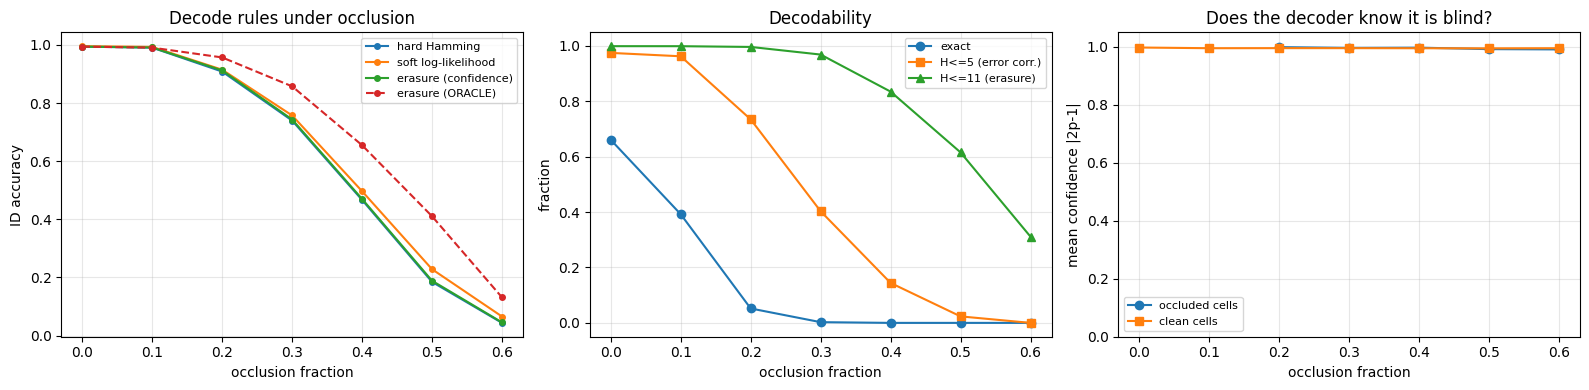

max ORACLE-erasure gain over hard : +22.58 pp   <- ceiling
max conf-erasure   gain over hard : +0.40 pp   <- what post-hoc thresholding achieves
max soft-LL        gain over hard : +4.37 pp

unrealised gap (oracle - confidence): +22.18 pp

CONTRIBUTION CONFIRMED. A large ceiling exists under occlusion, and post-hoc
confidence thresholding captures almost none of it. The paper is: erasures must
be LEARNED (explicit three-state decoder trained with occlusion), not thresholded.
The oracle arm is the ceiling; the confidence arm is the published-decoder floor.

saved -> C:/Users/hp/aruco_p2/artifacts/n2_occlusion.json


In [10]:
L_ = [r['level'] for r in rows]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for k, lbl, st in [('hard','hard Hamming','-'), ('soft','soft log-likelihood','-'),
                   ('e_conf','erasure (confidence)','-'), ('e_orac','erasure (ORACLE)','--')]:
    ax[0].plot(L_, [r[k] for r in rows], marker='o', ms=4, ls=st, label=lbl)
ax[0].set_xlabel('occlusion fraction'); ax[0].set_ylabel('ID accuracy')
ax[0].set_title('Decode rules under occlusion'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

ax[1].plot(L_, [r['exact'] for r in rows], marker='o', label='exact')
ax[1].plot(L_, [r['h5'] for r in rows], marker='s', label='H<=5 (error corr.)')
ax[1].plot(L_, [r['h11'] for r in rows], marker='^', label='H<=11 (erasure)')
ax[1].set_xlabel('occlusion fraction'); ax[1].set_ylabel('fraction')
ax[1].set_title('Decodability'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

ax[2].plot(L_, [d[2] for d in diag], marker='o', label='occluded cells')
ax[2].plot(L_, [d[3] for d in diag], marker='s', label='clean cells')
ax[2].set_ylim(0, 1.05); ax[2].set_xlabel('occlusion fraction')
ax[2].set_ylabel('mean confidence |2p-1|')
ax[2].set_title('Does the decoder know it is blind?'); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

gain_or = max((r['e_orac']-r['hard'])*100 for r in rows)
gain_cf = max((r['e_conf']-r['hard'])*100 for r in rows)
gain_sf = max((r['soft']-r['hard'])*100 for r in rows)
print(f'max ORACLE-erasure gain over hard : {gain_or:+.2f} pp   <- ceiling')
print(f'max conf-erasure   gain over hard : {gain_cf:+.2f} pp   <- what post-hoc thresholding achieves')
print(f'max soft-LL        gain over hard : {gain_sf:+.2f} pp')
print(f'\nunrealised gap (oracle - confidence): {gain_or-gain_cf:+.2f} pp\n')

if gain_or >= 8 and (gain_or - gain_cf) >= 5:
    print('CONTRIBUTION CONFIRMED. A large ceiling exists under occlusion, and post-hoc')
    print('confidence thresholding captures almost none of it. The paper is: erasures must')
    print('be LEARNED (explicit three-state decoder trained with occlusion), not thresholded.')
    print('The oracle arm is the ceiling; the confidence arm is the published-decoder floor.')
elif gain_or >= 8:
    print('Large ceiling AND post-hoc thresholding already captures much of it.')
    print('Contribution is smaller: report the threshold rule, no new training needed.')
elif gain_or >= 3:
    print('MODERATE ceiling. Erasure decoding is a section, not the headline.')
else:
    print('SMALL ceiling even with oracle erasures. Occlusion is not the venue;')
    print('pivot to corner refinement, which N1a suggested is the real bottleneck.')

json.dump({'levels': L_, 'tau': TAU,
           'rows': [{k: (float(v) if isinstance(v,(int,float,np.floating)) else v) for k,v in r.items()} for r in rows],
           'confidence_diagnostic': [[float(v) for v in d] for d in diag],
           'gains': {'oracle': float(gain_or), 'confidence': float(gain_cf), 'soft': float(gain_sf)},
           'decoder': 'DeepArUco++ published dec_new.h5', 'viewpoints': DEV, 'stride': STRIDE},
          open(f'{ART}/n2_occlusion.json','w'), indent=1)
print(f'\nsaved -> {ART}/n2_occlusion.json')